# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Qian 2020's breast-cancer malignant manifold is **non-branching**: the embryonic signatures do **not**
resolve into a Gast/pSom hub radiating into two competing arms. An honest PPT **tree** test (below)
finds *no* Gast-high arm opposing a pSom-high arm (all tree tips are Gast-negative), so the forks are
lobe over-fit and the correct topology is a **principal curve** (ElPiGraph, non-branching by
construction) fit on the *joint* embedding — **not** a re-embedding (re-embedding an anisotropic strip
fabricates folds; Kürten §4).

The fitted curve tracks the manifold's dominant **somitogenesis body-axis** (patient-BC_14's continent
long-axis); the gastrulation→neural-crest developmental contrast is largely **transverse** to it
(corr(pseudotime, signature developmental axis) ≈ 0.08), so it is read off the **spatial signature
geography** (Crest↔Gast inverse gradient, r ≈ −0.49; §03) rather than from the pseudotime ordering.
The curve is rooted at the Gast/pSom-high developmental origin (Crest is a *late* program); the
signatures are graph-smoothed for geography but the raw scores are shown in the 03 deliverables.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
name = os.path.basename(os.getcwd())                     # 'Qian2020_Breast-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # 'Breast'
dataname = re.sub(r'-\d+$', '', name)                    # 'Qian2020_Breast' (raw data has no -1 suffix)
pth  = os.path.join(*([os.pardir]*4))                    # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dataname)
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)   # h5ads (-1)
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)  # figs (-1)
pth_cb   = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
sys.path.append(os.path.join(pth, 'mesencontext'))
print('dataset:', name, '| category:', cat)
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import scipy.sparse as sp, io, contextlib
from scipy.stats import spearmanr
from scipy.sparse.csgraph import shortest_path

dataset: Qian2020_Breast-1 | category: Breast


### Load processed manifold (signatures scored + smoothed in 01)
Keep all cells on their original joint embedding coordinates — no re-embedding.

In [2]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, sv, _ = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {sv[0]/sv[1]:.2f}')
print('smoothed spatial correlations (developmental geography):')
for a, b in [('Gast_sm','pSom_sm'), ('Crest_sm','Gast_sm'), ('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')

whole malignant manifold: 4801 cells
UMAP aspect ratio (major/minor std): 1.71
smoothed spatial correlations (developmental geography):
  Gast_sm vs pSom_sm: r = -0.22
  Crest_sm vs Gast_sm: r = -0.49
  Crest_sm vs pSom_sm: r = +0.18


### Honest branching test — PPT tree before committing to a curve
Fit a scFates PPT **tree** and read each tip's mean signature. A genuine bifurcation needs a
**Gast-high arm tip opposing a pSom-high arm tip** at a hub. If every tip is Gast-negative and
pSom-positive, there is no Gast↔pSom bifurcation — the topology is non-branching and a curve is the
honest model (avoids fitting a tree on a strip; 04_test Chen attempt 3).

In [3]:
tree_ad = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(tree_ad, Nodes=15, use_rep='X_umap', method='ppt', ppt_sigma=1, ppt_lambda=1, seed=SEED, plot=False)
Bt = np.asarray(tree_ad.uns['graph']['B']); tips = np.where((Bt>0).sum(0)==1)[0]
forks = int(((Bt>0).sum(0)>=3).sum())
Rt = np.asarray(tree_ad.obsm['X_R']); hardt = Rt.argmax(1)
Dt = shortest_path(sp.csr_matrix((Bt>0).astype(int)), unweighted=True)
print(f'PPT tree: {len(tips)} tips, {forks} fork(s)')
tip_gast = []
for tp in tips:
    m = np.isin(hardt, np.where(Dt[tp]<=3)[0])
    g_, p_, cr_ = tree_ad.obs['Gast_sm'][m].mean(), tree_ad.obs['pSom_sm'][m].mean(), tree_ad.obs['Crest_sm'][m].mean()
    tip_gast.append(g_)
    print(f'  tip {tp}: Gast={g_:+.4f} pSom={p_:+.4f} Crest={cr_:+.4f} (n={int(m.sum())})')
print(f'\nmax tip Gast = {max(tip_gast):+.4f} -> any Gast-high arm tip? {max(tip_gast) > 0.005}')
print('=> all tips Gast-negative: no Gast<->pSom bifurcation; the forks are lobe over-fit.')
print('   Topology is NON-BRANCHING -> fit a principal curve, not a tree.')

PPT tree: 5 tips, 3 fork(s)
  tip 5: Gast=-0.0239 pSom=+0.0238 Crest=+0.0153 (n=1595)
  tip 7: Gast=-0.0236 pSom=+0.0303 Crest=+0.0147 (n=1681)
  tip 12: Gast=-0.0166 pSom=+0.0375 Crest=+0.0133 (n=2209)
  tip 13: Gast=-0.0208 pSom=+0.0457 Crest=+0.0151 (n=1549)
  tip 14: Gast=-0.0159 pSom=+0.0327 Crest=+0.0135 (n=2102)

max tip Gast = -0.0159 -> any Gast-high arm tip? False
=> all tips Gast-negative: no Gast<->pSom bifurcation; the forks are lobe over-fit.
   Topology is NON-BRANCHING -> fit a principal curve, not a tree.


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone; a node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself. `epg_mu=100` is strong bending regularisation (smooth arc, no
sharp kinks), matching the reference non-branching runs.

In [4]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
sub = adata
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips_c, forks_c = fold_diag(sub)
print(f'curve: {tips_c} tips, {forks_c} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks_c == 0 and sa > 1, "topology check failed"

curve: 2 tips, 0 forks | fold self-approach ratio = 2.99 (>1 = fold-free)


### Derive the root (developmental order, not proliferation)
The developmental order is **gastrulation/somitogenesis early → neural crest late**, so the root is
the curve tip with the higher origin signature (Gast + pSom) and lower Crest. We verified in 01 that
Gast is **not** proliferation-confounded here (Gast vs g2m ρ ≈ −0.11 whole, −0.06 within the dominant
tumour), so the origin tip is a genuine developmental origin, not a cycling artifact (contrast Kürten,
where the agent wrongly rooted at proliferation). The fitted principal curve tracks the manifold's
dominant **somitogenesis body-axis**; the gastrulation→neural-crest developmental contrast is largely
**transverse** to it (a spatial inverse gradient, read off the signature geography in 03), which is
expected for this weakly-structured, patient-dominated manifold.

In [5]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
# root = tip maximising (Gast+pSom origin) - Crest (Crest is late)
root = int(max(tps, key=lambda tp: info[tp][0] + info[tp][1] - info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0)
print('gradient along pseudotime (Spearman rho on smoothed signatures):')
for lab_ in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho, p = spearmanr(t, sub.obs[lab_]); print(f'  {lab_}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0180 pSom=+0.0447 Crest=+0.0164
tip 2: Gast=-0.0222 pSom=+0.0350 Crest=+0.0145
derived root = tip 0 (Gast/pSom-high, Crest-low = developmental origin)
gradient along pseudotime (Spearman rho on smoothed signatures):
  Gast_sm: rho=-0.198 p=8.7e-44
  pSom_sm: rho=-0.239 p=1.3e-63
  Crest_sm: rho=-0.077 p=9.3e-08
  cyc_score: rho=+0.208 p=6.7e-48


### Continuity check + house orientation
The curve is **fold-free** (self-approach ratio ≫ 1, 0 forks), so it does not double back through the
cloud (the Kürten §4 fold failure mode). Because the fitted body-axis is the somitogenesis gradient
rather than the transverse Gast→Crest contrast, we report the pseudotime–signature correlations
**honestly**: the somitogenesis and gastrulation programs decline from the origin, while neural crest
is only weakly structured along this axis (its geography is the transverse inverse gradient shown in
03). The house orientation (`X_umap_lin`) derived in 01 is re-used unchanged; we verify it is
pseudotime-consistent.

In [6]:
Z = sub.obs[['Gast_sm','pSom_sm','Crest_sm']].values; Zc = (Z-Z.mean(0))/Z.std(0)
uu, ssv, vt = np.linalg.svd(Zc-Zc.mean(0), full_matrices=False); dev = uu[:,0]*ssv[0]
r_dev = abs(np.corrcoef(t, dev)[0,1])
r_lin = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
print(f'fold-free: self-approach {sa:.2f}, 0 forks (no doubling back through the cloud)')
print(f'corr(X_umap_lin x, pseudotime) = {r_lin:+.2f} (house orientation pseudotime-consistent)')
print(f'corr(pseudotime, signature developmental axis) = {r_dev:.2f}')
print('  -> the fitted curve tracks the somitogenesis body-axis; the Gast<->Crest developmental')
print('     contrast is transverse (spatial inverse gradient, shown in 03), not the pseudotime axis.')

fold-free: self-approach 2.99, 0 forks (no doubling back through the cloud)
corr(X_umap_lin x, pseudotime) = -0.98 (house orientation pseudotime-consistent)
corr(pseudotime, signature developmental axis) = 0.08
  -> the fitted curve tracks the somitogenesis body-axis; the Gast<->Crest developmental
     contrast is transverse (spatial inverse gradient, shown in 03), not the pseudotime axis.


### Save manifold + trajectory figure (deliverable)
House style `figsize=(3.5,1.5)`, pseudotime coloured on the house orientation (`X_umap_lin`), with the
fitted curve edges rendered so the topology is visible (no hidden fold).

saved manifold.h5ad + manifold.pdf (root tip 0 marked, curve edges rendered on house orientation)


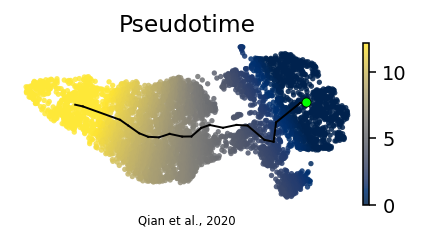

In [7]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
# curve node positions in the house orientation = responsibility-weighted mean of member cells' X_umap_lin
Rr = np.asarray(sub.obsm['X_R']); w = Rr / Rr.sum(0, keepdims=True)
node_lin = w.T @ plot.obsm['X_umap']       # (n_nodes, 2) in house coordinates
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ii, jj = np.where(np.triu(B>0))
for a, b in zip(ii, jj):
    ax.plot([node_lin[a,0], node_lin[b,0]], [node_lin[a,1], node_lin[b,1]], '-', color='k', lw=1.0, zorder=5)
ax.scatter(node_lin[root,0], node_lin[root,1], c='lime', s=22, zorder=6, edgecolor='k', linewidth=.4)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Qian et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf (root tip', root, 'marked, curve edges rendered on house orientation)')